# 0. download from TA's Google Drive

In [1]:
!gdown --id '19CzXudqN58R3D-1G8KeFWk8UDQwlb8is' --output food-11.zip # 下載資料集
!unzip food-11.zip # 解壓縮

Streaming output truncated to the last 5000 lines.
  inflating: food-11/training/4_165.jpg  
  inflating: food-11/training/5_376.jpg  
  inflating: food-11/training/2_691.jpg  
  inflating: food-11/training/0_541.jpg  
  inflating: food-11/training/3_482.jpg  
  inflating: food-11/training/0_227.jpg  
  inflating: food-11/training/5_410.jpg  
  inflating: food-11/training/4_603.jpg  
  inflating: food-11/training/8_341.jpg  
  inflating: food-11/training/5_1154.jpg  
  inflating: food-11/training/9_37.jpg  
  inflating: food-11/training/9_152.jpg  
  inflating: food-11/training/5_438.jpg  
  inflating: food-11/training/9_1287.jpg  
  inflating: food-11/training/8_369.jpg  
  inflating: food-11/training/2_1455.jpg  
  inflating: food-11/training/10_247.jpg  
  inflating: food-11/training/7_32.jpg  
  inflating: food-11/training/10_521.jpg  
  inflating: food-11/training/2_1333.jpg  
  inflating: food-11/training/2_861.jpg  
  inflating: food-11/training/0_569.jpg  
  inflating: food-11/

#1. Imports

In [2]:
import os
import numpy as np
import cv2
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import pandas as pd
from torch.utils.data import DataLoader, Dataset
import time

from google.colab.patches import cv2_imshow

#2. Read image

##2.X OpenCV (cv2)
利用 OpenCV (cv2) 讀入照片並存放在 numpy array 中

In [3]:
def readfile(path, label):
    # label 是一個 boolean variable，代表需不需要回傳 y 值
    image_dir = sorted(os.listdir(path))
    x = np.zeros((len(image_dir), 128, 128, 3), dtype=np.uint8)
    y = np.zeros((len(image_dir)), dtype=np.uint8)
    for i, file in enumerate(image_dir):
        img = cv2.imread(os.path.join(path, file))
        x[i, :, :] = cv2.resize(img,(128, 128))
        if label:
          y[i] = int(file.split("_")[0])
    if label:
      return x, y
    else:
      return x

In [4]:
# 分別將 training set、validation set、testing set 用 readfile 函式讀進來
workspace_dir = './food-11'
print("Reading data")
train_x, train_y = readfile(os.path.join(workspace_dir, "training"), True)
print("Size of training data = {}".format(len(train_x)))
val_x, val_y = readfile(os.path.join(workspace_dir, "validation"), True)
print("Size of validation data = {}".format(len(val_x)))
test_x = readfile(os.path.join(workspace_dir, "testing"), False)
print("Size of Testing data = {}".format(len(test_x)))

Reading data
Size of training data = 9866
Size of validation data = 3430
Size of Testing data = 3347


#### details: image data

In [5]:
from google.colab.patches import cv2_imshow

-rwxr-xr-x 1 root root 40146 Oct 24  2019 ./food-11/training/2_627.jpg
<class 'numpy.ndarray'>
shape= (512, 382, 3)


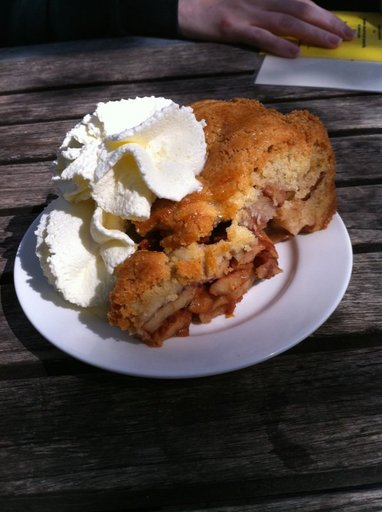

In [6]:
!ls -l ./food-11/training/2_627.jpg

tmp_img = cv2.imread("./food-11/training/2_627.jpg")
print(type(tmp_img))
print("shape=",tmp_img.shape)

cv2_imshow(tmp_img)

#3. Dataset (using PyTorch)
在 PyTorch 中，我們可以利用 torch.utils.data 的 Dataset 及 DataLoader 來"包裝" data，使後續的 training 及 testing 更為方便。

Dataset 需要 overload 兩個函數：\_\_len\_\_ 及 \_\_getitem\_\_

\_\_len\_\_ 必須要回傳 dataset 的大小，而 \_\_getitem\_\_ 則定義了當程式利用 [ ] 取值時，dataset 應該要怎麼回傳資料。

實際上我們並不會直接使用到這兩個函數，但是使用 DataLoader 在 enumerate Dataset 時會使用到，沒有實做的話會在程式運行階段出現 error。


In [7]:
# training 時做 data augmentation
train_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(), # 隨機將圖片水平翻轉
    transforms.RandomRotation(15), # 隨機旋轉圖片
    transforms.ToTensor(), # 將圖片轉成 Tensor，並把數值 normalize 到 [0,1] (data normalization)
])
# testing 時不需做 data augmentation
test_transform = transforms.Compose([
    transforms.ToPILImage(),                                    
    transforms.ToTensor(),
])
class ImgDataset(Dataset):
    def __init__(self, x, y=None, transform=None):
        self.x = x
        # label is required to be a LongTensor
        self.y = y
        if y is not None:
            self.y = torch.LongTensor(y)
        self.transform = transform
    def __len__(self):
        return len(self.x)
    def __getitem__(self, index):
        X = self.x[index]
        if self.transform is not None:
            X = self.transform(X)
        if self.y is not None:
            Y = self.y[index]
            return X, Y
        else:
            return X

In [8]:
batch_size = 128
train_set = ImgDataset(train_x, train_y, train_transform)
val_set = ImgDataset(val_x, val_y, test_transform)
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)

#4. Model

In [9]:
class Classifier(nn.Module):
    def __init__(self):
        super(Classifier, self).__init__()
        # torch.nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)
        # torch.nn.MaxPool2d(kernel_size, stride, padding)
        # input 維度 [3, 128, 128]
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 64, 3, 1, 1),  # [64, 128, 128]
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [64, 64, 64]

            nn.Conv2d(64, 128, 3, 1, 1), # [128, 64, 64]
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [128, 32, 32]

            nn.Conv2d(128, 256, 3, 1, 1), # [256, 32, 32]
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),      # [256, 16, 16]

            nn.Conv2d(256, 512, 3, 1, 1), # [512, 16, 16]
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),       # [512, 8, 8]
            
            nn.Conv2d(512, 512, 3, 1, 1), # [512, 8, 8]
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2, 2, 0),       # [512, 4, 4]
        )
        self.fc = nn.Sequential(
            nn.Linear(512*4*4, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 11)
        )

    def forward(self, x):
        out = self.cnn(x)
        out = out.view(out.size()[0], -1)
        return self.fc(out)

#5. Training

* find parameters

In [10]:
model = Classifier().cuda()
loss = nn.CrossEntropyLoss() # 因為是 classification task，所以 loss 使用 CrossEntropyLoss
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) # optimizer 使用 Adam
num_epoch = 30

for epoch in range(num_epoch):
    epoch_start_time = time.time()
    train_acc = 0.0
    train_loss = 0.0
    val_acc = 0.0
    val_loss = 0.0

    model.train() # 確保 model 是在 train model (開啟 Dropout 等...)
    for i, data in enumerate(train_loader):
        optimizer.zero_grad() # 用 optimizer 將 model 參數的 gradient 歸零
        train_pred = model(data[0].cuda()) # 利用 model 得到預測的機率分佈 這邊實際上就是去呼叫 model 的 forward 函數
        batch_loss = loss(train_pred, data[1].cuda()) # 計算 loss （注意 prediction 跟 label 必須同時在 CPU 或是 GPU 上）
        batch_loss.backward() # 利用 back propagation 算出每個參數的 gradient
        optimizer.step() # 以 optimizer 用 gradient 更新參數值

        train_acc += np.sum(np.argmax(train_pred.cpu().data.numpy(), axis=1) == data[1].numpy())
        train_loss += batch_loss.item()
    
    model.eval()
    with torch.no_grad():
        for i, data in enumerate(val_loader):
            val_pred = model(data[0].cuda())
            batch_loss = loss(val_pred, data[1].cuda())

            val_acc += np.sum(np.argmax(val_pred.cpu().data.numpy(), axis=1) == data[1].numpy())
            val_loss += batch_loss.item()

        #將結果 print 出來
        print('[%03d/%03d] %2.2f sec(s) Train Acc: %3.6f Loss: %3.6f | Val Acc: %3.6f loss: %3.6f' % \
            (epoch + 1, num_epoch, time.time()-epoch_start_time, \
             train_acc/train_set.__len__(), train_loss/train_set.__len__(), val_acc/val_set.__len__(), val_loss/val_set.__len__()))

[001/030] 37.58 sec(s) Train Acc: 0.213055 Loss: 0.018677 | Val Acc: 0.213411 loss: 0.017602
[002/030] 37.27 sec(s) Train Acc: 0.306811 Loss: 0.015441 | Val Acc: 0.296793 loss: 0.015428
[003/030] 37.36 sec(s) Train Acc: 0.366511 Loss: 0.014252 | Val Acc: 0.328863 loss: 0.014779
[004/030] 37.41 sec(s) Train Acc: 0.415467 Loss: 0.013159 | Val Acc: 0.362974 loss: 0.015389
[005/030] 37.44 sec(s) Train Acc: 0.459659 Loss: 0.012236 | Val Acc: 0.375802 loss: 0.015001
[006/030] 37.48 sec(s) Train Acc: 0.490472 Loss: 0.011645 | Val Acc: 0.307872 loss: 0.017258
[007/030] 37.39 sec(s) Train Acc: 0.519055 Loss: 0.010892 | Val Acc: 0.413994 loss: 0.013598
[008/030] 37.49 sec(s) Train Acc: 0.545104 Loss: 0.010241 | Val Acc: 0.502041 loss: 0.011821
[009/030] 37.49 sec(s) Train Acc: 0.568315 Loss: 0.009776 | Val Acc: 0.545773 loss: 0.010650
[010/030] 37.47 sec(s) Train Acc: 0.585445 Loss: 0.009357 | Val Acc: 0.557434 loss: 0.010315
[011/030] 37.28 sec(s) Train Acc: 0.618184 Loss: 0.008798 | Val Acc: 0

* train whole dataset

In [11]:
train_val_x = np.concatenate((train_x, val_x), axis=0)
train_val_y = np.concatenate((train_y, val_y), axis=0)
train_val_set = ImgDataset(train_val_x, train_val_y, train_transform)
train_val_loader = DataLoader(train_val_set, batch_size=batch_size, shuffle=True)

In [12]:
model_best = Classifier().cuda()
loss = nn.CrossEntropyLoss() # 因為是 classification task，所以 loss 使用 CrossEntropyLoss
optimizer = torch.optim.Adam(model_best.parameters(), lr=0.001) # optimizer 使用 Adam
num_epoch = 30

for epoch in range(num_epoch):
    epoch_start_time = time.time()
    train_acc = 0.0
    train_loss = 0.0

    model_best.train()
    for i, data in enumerate(train_val_loader):
        optimizer.zero_grad()
        train_pred = model_best(data[0].cuda())
        batch_loss = loss(train_pred, data[1].cuda())
        batch_loss.backward()
        optimizer.step()

        train_acc += np.sum(np.argmax(train_pred.cpu().data.numpy(), axis=1) == data[1].numpy())
        train_loss += batch_loss.item()

        #將結果 print 出來
    print('[%03d/%03d] %2.2f sec(s) Train Acc: %3.6f Loss: %3.6f' % \
      (epoch + 1, num_epoch, time.time()-epoch_start_time, \
      train_acc/train_val_set.__len__(), train_loss/train_val_set.__len__()))

[001/030] 46.11 sec(s) Train Acc: 0.233830 Loss: 0.017578
[002/030] 46.06 sec(s) Train Acc: 0.356498 Loss: 0.014228
[003/030] 46.09 sec(s) Train Acc: 0.427422 Loss: 0.012804
[004/030] 46.05 sec(s) Train Acc: 0.471119 Loss: 0.011767
[005/030] 46.09 sec(s) Train Acc: 0.521736 Loss: 0.010839
[006/030] 45.98 sec(s) Train Acc: 0.561898 Loss: 0.009849
[007/030] 45.74 sec(s) Train Acc: 0.597172 Loss: 0.009193
[008/030] 45.70 sec(s) Train Acc: 0.623797 Loss: 0.008492
[009/030] 45.71 sec(s) Train Acc: 0.642750 Loss: 0.008056
[010/030] 45.65 sec(s) Train Acc: 0.665012 Loss: 0.007562
[011/030] 45.69 sec(s) Train Acc: 0.687876 Loss: 0.007007
[012/030] 45.68 sec(s) Train Acc: 0.702768 Loss: 0.006747
[013/030] 45.69 sec(s) Train Acc: 0.716306 Loss: 0.006363
[014/030] 45.62 sec(s) Train Acc: 0.731197 Loss: 0.005999
[015/030] 45.65 sec(s) Train Acc: 0.750451 Loss: 0.005626
[016/030] 45.77 sec(s) Train Acc: 0.771209 Loss: 0.005181
[017/030] 45.83 sec(s) Train Acc: 0.780535 Loss: 0.004931
[018/030] 45.7

#6. Testing

In [13]:
test_set = ImgDataset(test_x, transform=test_transform)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

In [14]:
model_best.eval()
prediction = []
with torch.no_grad():
    for i, data in enumerate(test_loader):
        test_pred = model_best(data.cuda())
        test_label = np.argmax(test_pred.cpu().data.numpy(), axis=1)
        for y in test_label:
            prediction.append(y)

In [15]:
#將結果寫入 csv 檔
with open("predict.csv", 'w') as f:
    f.write('Id,Category\n')
    for i, y in  enumerate(prediction):
        f.write('{},{}\n'.format(i, y))

In [16]:
!cat predict.csv | head -100

Id,Category
0,3
1,10
2,8
3,9
4,7
5,3
6,9
7,10
8,2
9,2
10,1
11,0
12,5
13,10
14,8
15,4
16,9
17,4
18,5
19,9
20,3
21,5
22,3
23,3
24,9
25,3
26,10
27,4
28,5
29,8
30,5
31,9
32,2
33,2
34,2
35,9
36,5
37,10
38,10
39,2
40,4
41,2
42,2
43,5
44,5
45,1
46,10
47,3
48,0
49,9
50,10
51,1
52,3
53,8
54,0
55,8
56,5
57,9
58,7
59,9
60,5
61,8
62,2
63,3
64,10
65,8
66,1
67,9
68,4
69,10
70,2
71,5
72,5
73,8
74,9
75,7
76,4
77,9
78,9
79,9
80,0
81,1
82,9
83,8
84,6
85,0
86,4
87,4
88,9
89,5
90,8
91,4
92,0
93,9
94,5
95,6
96,1
97,9
98,6


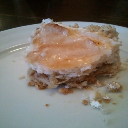

In [25]:
cv2_imshow(test_x[0])